# Least Squares Havlena and Odeh

In [16]:
import numpy as np
import pandas as pd
from pandas import Series, DataFrame
import matplotlib.pyplot as plt

In [17]:
#Data Table 3.1
N = 115E6
Pressure = [3330, 3150, 3000, 2850, 2700, 2550, 2400]
Np = [np.nan, 3.295, 5.903, 8.852, 11.503, 14.513, 17.73]
Rp = [np.nan, 1050, 1060, 1160, 1235, 1265, 1300]
Bo = [1.2511, 1.2353, 1.2222, 1.2122, 1.2022, 1.1922, 1.1822]
Rs = [510, 477, 450, 425, 401, 375, 352]
Bg = [0.00087, 0.00092, 0.00096, 0.00101, 0.00107, 0.00113, 0.0012]
data = {"Np": Np,
        "Rp": Rp,
        "Bo": Bo,
        "Rs": Rs,
        "Bg": Bg}
table1 = pd.DataFrame(data, index = Pressure)
table1.index.name = "Pressure"
table1

,Np,Rp,Bo,Rs,Bg
Pressure,,,,,
3330,NaN,NaN,1.2511,510,0.00087
3150,3.295,1050.0,1.2353,477,0.00092
3000,5.903,1060.0,1.2222,450,0.00096
2850,8.852,1160.0,1.2122,425,0.00101
2700,11.503,1235.0,1.2022,401,0.00107
2550,14.513,1265.0,1.1922,375,0.00113
2400,17.730,1300.0,1.1822,352,0.00120


In [18]:
Boi = table1.iloc[0]["Bo"]
Rsi = table1.iloc[0]["Rs"]
Bgi = table1.iloc[0]["Bg"]
table2 = pd.DataFrame(index = Pressure)
table2.index.name = "Pressure [psia]"
table2["F"] = table1["Np"] * (table1["Bo"] + (table1["Rp"] - table1["Rs"]) * table1["Bg"]) #Underground Withdrawal
table2["Eo"] = table1["Bo"] - Boi + (Rsi - table1["Rs"]) * table1["Bg"] #Expansion of oil and gas liberation
table2["Eg"] = Boi * (table1["Bg"] / Bgi - 1)#Expansion of gas cap

m_values = [0.4, 0.5, 0.6]
for m in m_values:
    table2[f"m = {m}"] = table2["Eo"] + m * table2["Eg"]
for m in m_values:
    table2[f"N, m = {m}"] = table2["F"] / table2[f"m = {m}"]
table2

,F,Eo,Eg,m = 0.4,m = 0.5,m = 0.6,"N, m = 0.4","N, m = 0.5","N, m = 0.6"
Pressure [psia],,,,,,,,,
3330,NaN,0.00000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
3150,5.807306,0.01456,0.071902,0.043321,0.050511,0.057701,134.053149,114.970769,100.644140
3000,10.671443,0.02870,0.129424,0.080470,0.093412,0.106354,132.614504,114.240521,100.338445
2850,17.301677,0.04695,0.201326,0.127481,0.147613,0.167746,135.720102,117.209534,103.142196
2700,24.093954,0.06773,0.287609,0.182774,0.211535,0.240296,131.823980,113.900771,100.268012
2550,31.898123,0.09365,0.373892,0.243207,0.280596,0.317985,131.156387,113.679900,100.313239
2400,41.130054,0.12070,0.474555,0.310522,0.357978,0.405433,132.454528,114.895612,101.447202


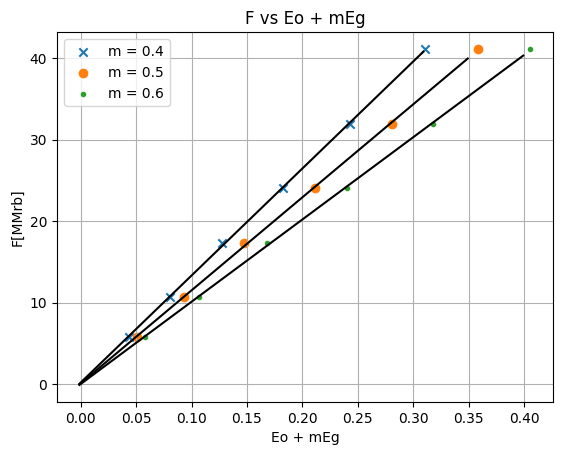

In [19]:
y = table2["F"]
plt.scatter(table2["m = 0.4"],y , marker = "x",)
plt.scatter(table2["m = 0.5"],y , marker = "o")
plt.scatter(table2["m = 0.6"],y , marker = ".")

m_values = [0.4, 0.5, 0.6]
for value in m_values:
    x = table2[f"m = {value}"][1:]
    y = table2["F"][1:]
    slope, intercept = np.polyfit(x, y, 1)
    x1 = np.arange(-0.001, np.max(x), 0.01)
    y1 = slope * x1 + intercept
    plt.plot(x1, y1, color = "k")

plt.xlabel('Eo + mEg')
plt.ylabel("F[MMrb]")
plt.title('F vs Eo + mEg')
plt.legend(table2.columns[3:6])
plt.grid(True)

In [20]:
table3 = pd.DataFrame(index = Pressure)
table3.index.name = "Pressure"
table3["F/Eo"] = table2["F"] / table2["Eo"]
table3["Eg/Eo"] = table2["Eg"] / table2["Eo"]
table3

,F/Eo,Eg/Eo
Pressure,,
3330,NaN,NaN
3150,398.853413,4.938345
3000,371.827296,4.509552
2850,368.512814,4.288103
2700,355.735328,4.246408
2550,340.609959,3.992439
2400,340.762668,3.931692


## Answer

In [21]:
x = (np.array(table3[1:]["Eg/Eo"]))
y = (np.array(table3[1:]["F/Eo"]))

In [22]:
tableLS = pd.DataFrame(index = np.arange(np.count_nonzero(x)))
tableLS["x"] = x
tableLS["y"] = y
tableLS["xy"] = x * y
tableLS["x^2"] = x ** 2
tableLS["y^2"] = y ** 2
n = np.count_nonzero(x)
tableLS.loc["Sum"] = tableLS.sum()
tableLS

,x,y,xy,x^2,y^2
0,4.938345,398.853413,1969.675641,24.387248,159084.045430
1,4.509552,371.827296,1676.774469,20.336058,138255.538175
2,4.288103,368.512814,1580.220909,18.387828,135801.693811
3,4.246408,355.735328,1510.597244,18.031979,126547.623320
4,3.992439,340.609959,1359.864637,15.939573,116015.144458
5,3.931692,340.762668,1339.773708,15.458199,116119.195747
Sum,25.906538,2176.301478,9436.906609,112.540884,791823.240941


#### Manual Least Squares Method

In [23]:
slope = (n * tableLS["xy"]["Sum"] - tableLS["x"]["Sum"] * tableLS["y"]["Sum"]) / (n * tableLS["x^2"]["Sum"] - tableLS["x"]["Sum"] ** 2)
intercept = (tableLS["y"]["Sum"] - slope * tableLS["x"]["Sum"]) / n
print(f"a = {slope:.5f}, b = {intercept:.5f}")

a = 58.83013, b = 108.70273


#### Least Squares With np.polyfit()

In [24]:
x = table3[1:]["Eg/Eo"]
y = table3[1:]["F/Eo"]
slope, intercept = np.polyfit(x, y ,1)
print(f"a = {slope:.5f}, b = {intercept:.5f}")

a = 58.83013, b = 108.70273


### m computation
##### F/Eo = N + mNEg/Eo
##### m = mN / N
##### m = slope / intercept

In [25]:
m = slope / intercept 

In [26]:
print(f"m = {m:.4f}")

m = 0.5412


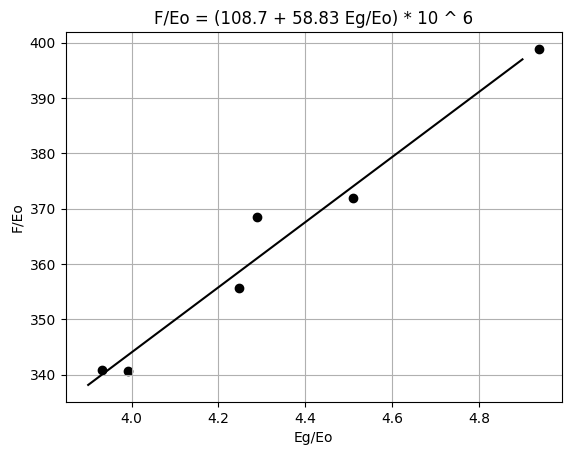

In [10]:
x = table3["Eg/Eo"]
y = table3["F/Eo"]

x1 = np.arange(3.9, 5,0.2)
y2 = slope * x1 + intercept

plt.scatter(x, y, marker = "o", color = "k")
plt.plot(x1, y2, color = "k")

plt.xlabel('Eg/Eo')
plt.ylabel('F/Eo')
plt.title(f'F/Eo = ({intercept:.1f} + {slope:.2f} Eg/Eo) * 10 ^ 6')
plt.grid(True)